

---


# Bidirectional LSTM (Bi-LSTM)

---


- by: Marchell Adi Pratama (672023081) & Gemini AI | vibe coder 😁
- suggester: Greysen Wijaya Liunesi (672023174)  


---



0. IMPORT LIBRARY

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

1. SETUP DATA

In [ ]:
# Load data yang sudah siap
df = pd.read_csv('dataset_lengkap_lstm.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date')

print("Data siap ditraining!")
print(df.head())

# Tentukan Fitur (X) dan Target (y)
# Target: Harga Beras besok
# Fitur: Harga Beras hari ini, Hujan, Suhu, Kurs, Libur
features = ['Harga_Beras', 'Curah_Hujan', 'Suhu', 'Kurs_USD', 'Is_Holiday']
data_values = df[features].values

# Normalisasi (Wajib buat LSTM biar ga pusing hitung angka ribuan vs angka 0.x)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data_values)

Data siap ditraining!
             Harga_Beras  Curah_Hujan   Suhu      Kurs_USD  Is_Holiday
Date                                                                  
2020-01-02  11466.666667         6.77  27.38  13689.231445           0
2020-01-03  11550.000000        51.20  27.25  13884.786133           0
2020-01-04  11527.777778         9.00  27.21  13884.786133           0
2020-01-05  11505.555556        10.65  27.10  13884.786133           0
2020-01-06  11483.333333         7.20  27.54  13934.316406           0


2. MEMBUAT JENDELA WAKTU (SLIDING WINDOW)

In [ ]:
def create_sequences(data, time_steps=30):
    X, y = [], []
    for i in range(len(data) - time_steps):
        # Ambil data 30 hari ke belakang (Semua fitur)
        X.append(data[i:(i + time_steps), :])
        # Ambil Harga Beras (Kolom ke-0) untuk hari esok
        y.append(data[i + time_steps, 0])
    return np.array(X), np.array(y)

# Kita pakai memori 30 hari ke belakang untuk prediksi besok
TIME_STEPS = 30
X, y = create_sequences(scaled_data, TIME_STEPS)

# Split Data: 80% Training, 20% Testing
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Shape Training: {X_train.shape}")
print(f"Shape Testing: {X_test.shape}")

Shape Training: (1696, 30, 5)
Shape Testing: (425, 30, 5)


3. ARSITEKTUR BI-LSTM (CORE DEEP LEARNING)

In [ ]:
model = Sequential()

# Layer 1: Bidirectional LSTM (Bisa baca konteks masa lalu & masa depan)
model.add(Bidirectional(LSTM(units=64, return_sequences=True), input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2)) # Biar ga overfitting

# Layer 2: LSTM Biasa
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))

# Output Layer (Prediksi 1 angka: Harga)
model.add(Dense(units=1))

model.compile(optimizer='adam', loss='mean_squared_error')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


4. TRAINING MODEL

In [ ]:
# Early Stopping: Berhenti kalau model ga tambah pinter (biar hemat waktu)
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

print("\nMulai Training...)")
history = model.fit(
    X_train, y_train,
    epochs=50,         # Coba 50 epoch dulu
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)


Mulai Training...)
Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - loss: 0.0561 - val_loss: 0.0014
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0052 - val_loss: 5.7745e-04
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.0039 - val_loss: 4.1017e-04
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0040 - val_loss: 5.3071e-04
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 0.0038 - val_loss: 3.6347e-04
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0035 - val_loss: 1.2689e-04
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 0.0027 - val_loss: 0.0033
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0029 - val_loss: 1.5742e-04
Epoch 9/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0032 - val_loss: 1.5324e-04
Epoch 10/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - loss: 0.0031 - val_loss: 0.0010
Epoch 11/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 0.0034 - val_loss: 0.0014
Epoch 12/50
53/

5. EVALUASI & VISUALISASI

In [ ]:
# Prediksi harga untuk data testing
predictions = model.predict(X_test)

# Balikin skala angka (Inverse Transform) biar jadi Rupiah lagi
# Kita harus bikin dummy array karena scaler butuh 5 kolom, tapi prediksi cuma 1 kolom
pred_expand = np.zeros((len(predictions), len(features)))
pred_expand[:, 0] = predictions[:, 0] # Masukkan prediksi ke kolom Harga
pred_real = scaler.inverse_transform(pred_expand)[:, 0]

# Balikin skala data asli (Target Y)
y_test_expand = np.zeros((len(y_test), len(features)))
y_test_expand[:, 0] = y_test
y_actual = scaler.inverse_transform(y_test_expand)[:, 0]

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


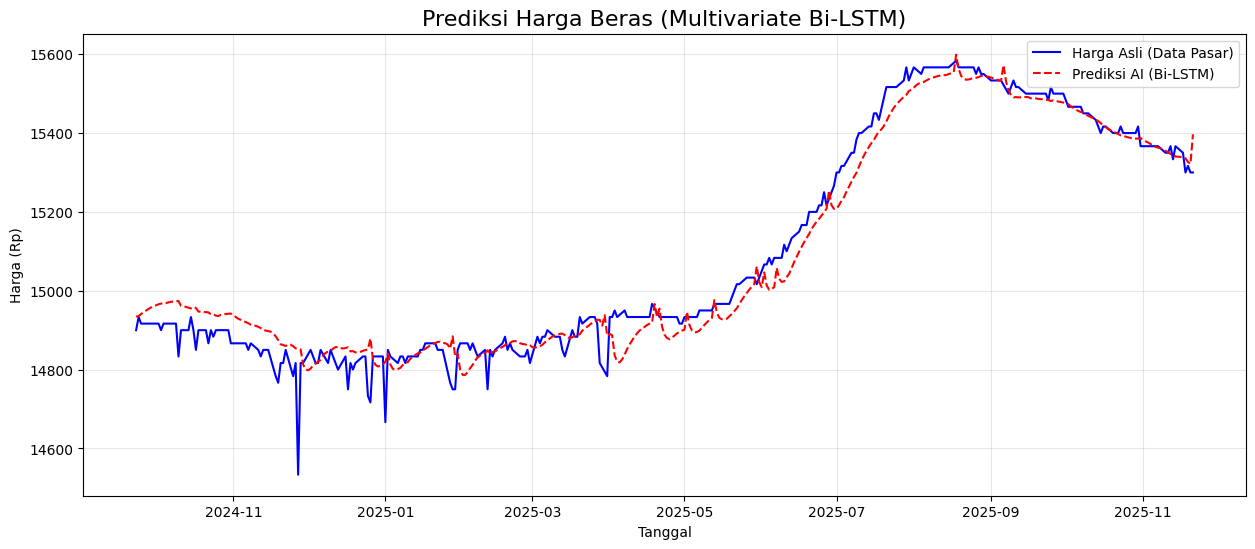

In [ ]:
# Plotting Hasil Akhir
plt.figure(figsize=(15, 6))
plt.plot(df.index[train_size + TIME_STEPS:], y_actual, color='blue', label='Harga Asli (Data Pasar)')
plt.plot(df.index[train_size + TIME_STEPS:], pred_real, color='red', linestyle='--', label='Prediksi AI (Bi-LSTM)')
plt.title('Prediksi Harga Beras (Multivariate Bi-LSTM)', fontsize=16)
plt.xlabel('Tanggal')
plt.ylabel('Harga (Rp)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

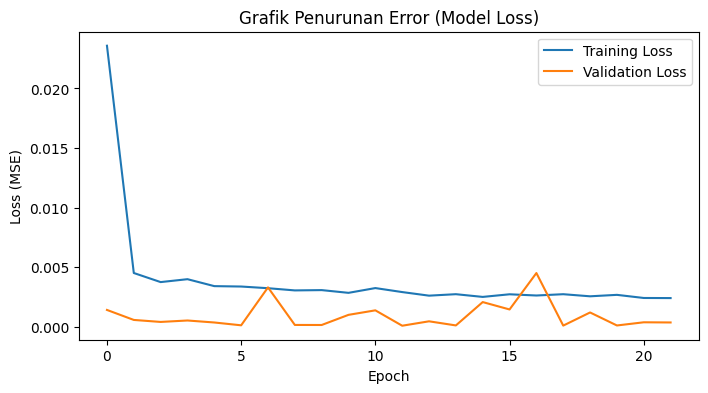

In [ ]:
# Plot Loss
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Grafik Penurunan Error (Model Loss)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()